In [1]:
#importing the necessary packages
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#reading the provided .csv dataset
data=pd.read_csv("/content/LoanApprovalPrediction.csv")

In [3]:
#displaying the first few records of the dataset
data.head() #bydefault the first 5 rows are displayed using .head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
data.head(15) #here first 15 records will be displayed

In [4]:
#Q. Number of customers whose application has been approved and for those whose application is not approved ?
data["Loan_Status"].value_counts()

,count
Loan_Status,
Y,411
N,187


In [5]:
data['Married'].value_counts()

,count
Married,
Yes,388
No,210


In [6]:
data.describe() #helpful for showcasing the statistical relationships between different numeric columns of the dataset

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,586.000000,598.000000,598.000000,577.000000,584.000000,549.000000
mean,0.755973,5292.252508,1631.499866,144.968804,341.917808,0.843352
std,1.007751,5807.265364,2953.315785,82.704182,65.205994,0.363800
min,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000
25%,0.000000,2877.500000,0.000000,100.000000,360.000000,1.000000
50%,0.000000,3806.000000,1211.500000,127.000000,360.000000,1.000000
75%,1.750000,5746.000000,2324.000000,167.000000,360.000000,1.000000
max,3.000000,81000.000000,41667.000000,650.000000,480.000000,1.000000


Since the ML-DL algorithms are unable to process categorical columns, we will need to convert the categorical columns into numeric so that the numeric representation will be then useful for further analysis and interpretation. We can do this conversion using one of the following techniques:

- Label Encoding
- One Hot Encoding

In [7]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()

In [8]:
data['Married'].unique() #helpful for showcasing the unique categories available in any given column

array(['No', 'Yes'], dtype=object)

In [9]:
data['Married']=le.fit_transform(data['Married'])

In [11]:
data['Married'].unique() #No - 0 and Yes - 1

array([0, 1])

In [12]:
data['Property_Area'].unique()

array(['Urban', 'Rural', 'Semiurban'], dtype=object)

In [13]:
data['Property_Area']=le.fit_transform(data['Property_Area'])

In [14]:
data['Property_Area'].unique()

array([2, 0, 1])

In [15]:
#Creating a new combined column called - Total Income
data['Total_Income']=data['ApplicantIncome']+data['CoapplicantIncome']

In [16]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income
0,LP001002,Male,0,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,2,Y,5849.0
1,LP001003,Male,1,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,0,N,6091.0
2,LP001005,Male,1,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,2,Y,3000.0
3,LP001006,Male,1,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,2,Y,4941.0
4,LP001008,Male,0,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,2,Y,6000.0


In [17]:
#Removing existing columns - ApplicantIncome and CoapplicantIncome
data=data.drop(['CoapplicantIncome'],axis=1)

In [18]:
data=data.drop(['ApplicantIncome'],axis=1)

In [19]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income
0,LP001002,Male,0,0.0,Graduate,No,NaN,360.0,1.0,2,Y,5849.0
1,LP001003,Male,1,1.0,Graduate,No,128.0,360.0,1.0,0,N,6091.0
2,LP001005,Male,1,0.0,Graduate,Yes,66.0,360.0,1.0,2,Y,3000.0
3,LP001006,Male,1,0.0,Not Graduate,No,120.0,360.0,1.0,2,Y,4941.0
4,LP001008,Male,0,0.0,Graduate,No,141.0,360.0,1.0,2,Y,6000.0


In [20]:
#Bar Graph for repsenting the approved vs rejected loan applications
approved=(data['Loan_Status']=='Y').sum()
rejected=(data['Loan_Status']=='N').sum()

In [23]:
labels=['Approved','Rejected']
values=[approved,rejected]

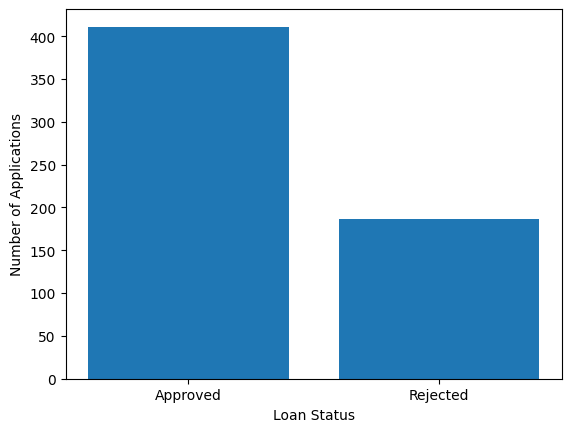

In [24]:
plt.bar(labels,values)
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()